# Graphettes: Dense, Sparse, Star, and Ring Structures

A **graphette** is a graph sampled from a triple $(W, \rho_n, f)$:

- $W$ -- a dense graphon (values in $(0,1)$),
- $\rho_n$ -- a *sparsity function* of $n$ (the number of nodes). $\rho_n \equiv 1$ gives an ordinary dense graphon sample; a $\rho_n \to 0$ (e.g. $\rho_n(n) = c/n$) rescales $W$ down so the graph gets sparser as it grows -- a standard way to move a graphon model out of the "dense" regime,
- $f$ -- an optional **graph edit function**, applied after sampling. For example, it can graft extra **star** structure (new hub nodes) onto existing nodes, add in small **ring** (cycle) subgraphs, or strip all cycles out entirely (reducing the graph to a spanning tree/forest).

This notebook builds:
1. a **dense** graph and a **sparse** graph from the same base graphon, to see the contrast,
2. graphs with extra **star** (hub) structure grafted on, at a few different hub strengths,
3. graphs with extra **ring** structure spliced in.

All functions come from `Graphon_Mixtures_Graphettes.py`, next to this notebook.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import igraph as ig
import sys
sys.path.insert(0, "../src")

from Graphon_Mixtures_Graphettes import (
    sample_sparse_graphon,
    sample_graphette,
    ring_graphon,
    plot_graphon,
    STAR_FUNCTIONS,
)

%matplotlib inline
rng = np.random.default_rng(0)


def plot_graph(gr, ax, title, layout="fr", color_by_degree=True):
    """Small helper: lay out and draw an igraph graph, optionally coloring by degree."""
    deg = np.array(gr.degree())
    if color_by_degree and deg.max() > 0:
        sizes = 4 + 20 * (deg / deg.max()) ** 0.6
        cmap = plt.get_cmap("plasma")
        colors = [cmap(d) for d in deg / deg.max()]
    else:
        sizes = 6
        colors = "black"
    lay = gr.layout(layout)
    ig.plot(gr, target=ax, layout=lay, vertex_size=sizes, vertex_color=colors,
            edge_color=(0.6, 0.6, 0.6, 0.5), edge_width=0.6)
    ax.set_title(title)

## 1. Dense vs. sparse

We start from the same base graphon (a ring graphon -- edge probability depends on how close two points are on a circle) and sample both a plain dense graph ($\rho_n \equiv 1$) and a sparsified one ($\rho_n(n) = c/n$, so overall density shrinks as $n$ grows).

In [21]:
W = ring_graphon(80, alpha=0.1)

n = 150
gr_dense = sample_sparse_graphon(W, rho_n=None, n=n, rng=rng)          # rho_n = 1 (dense)
gr_sparse = sample_sparse_graphon(W, rho_n=lambda k: 15 / k, n=n, rng=rng)  # shrinks with n

print(f"Dense:  {gr_dense.vcount()} nodes, {gr_dense.ecount()} edges, "
      f"mean degree {2*gr_dense.ecount()/gr_dense.vcount():.2f}")
print(f"Sparse: {gr_sparse.vcount()} nodes, {gr_sparse.ecount()} edges, "
      f"mean degree {2*gr_sparse.ecount()/gr_sparse.vcount():.2f}")

Dense:  150 nodes, 2440 edges, mean degree 32.53
Sparse: 150 nodes, 232 edges, mean degree 3.09


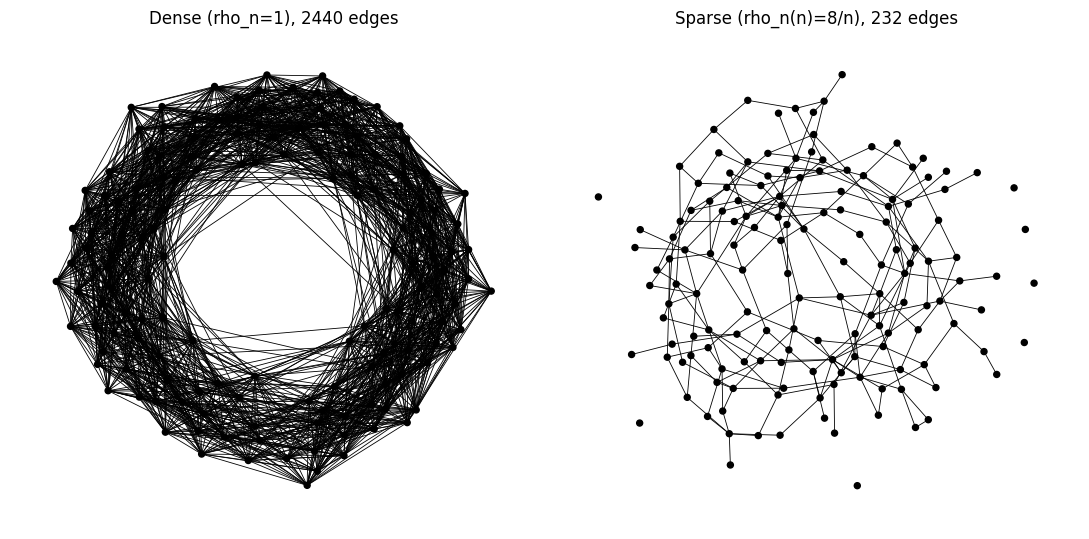

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
plot_graph(gr_dense, axes[0], f"Dense (rho_n=1), {gr_dense.ecount()} edges", color_by_degree=False)
plot_graph(gr_sparse, axes[1], f"Sparse (rho_n(n)=8/n), {gr_sparse.ecount()} edges", color_by_degree=False)
plt.tight_layout()
plt.show()

Same underlying graphon shape (the ring), same number of nodes -- but the sparsified version has a fraction of the edges, giving a much looser, more thread-like layout instead of a dense ring-shaped network. Also the ring structure is not as apparent in the sparser version. 

## 2. Adding star (hub) structure

`sample_graphette` can graft extra hub structure onto a sampled graph: for each existing node $i$ at graphon position $x_i$, it draws $\text{Poisson}(\text{star\_f}(x_i, t))$ new leaf vertices and attaches them to $i$. `t` controls hub strength. We use `star_f1`, which decays with $x$ -- so nodes near $x=0$ get the most extra hub edges.

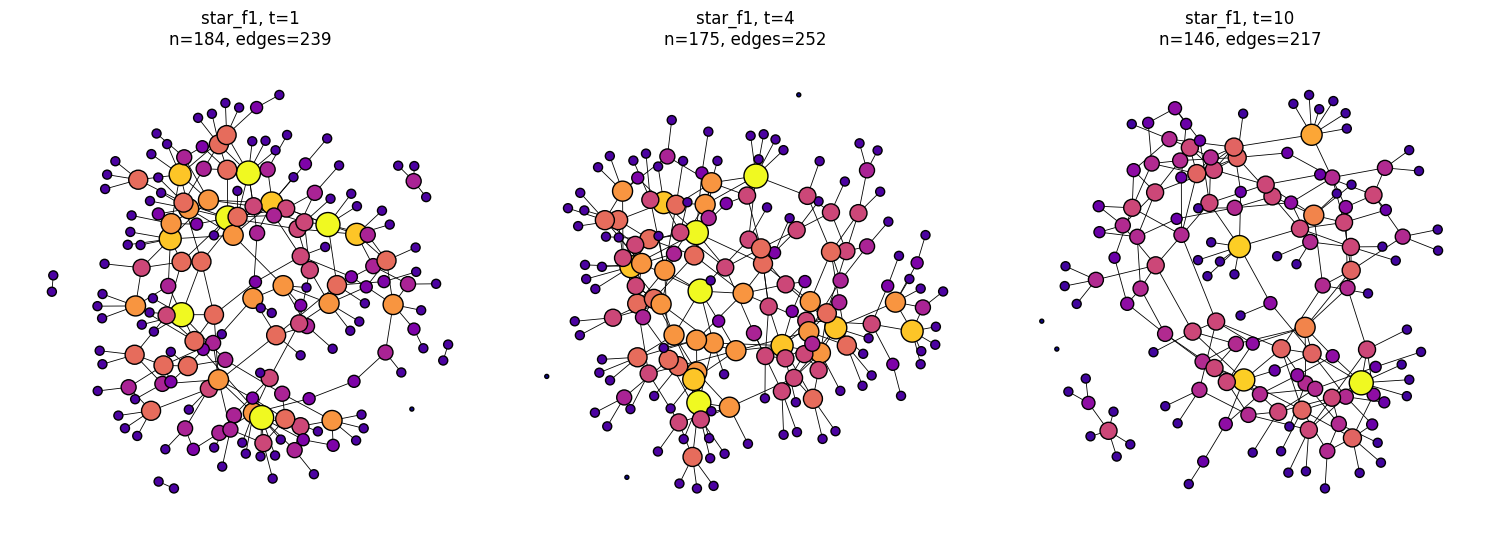

In [28]:
rho = lambda k: 15.0 / k
ts = [1, 4, 10]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, t in zip(axes, ts):
    gr = sample_graphette(W, rho_n=rho, graph_edit_f="star_f1", n=100, t_or_p=t/2, rng=rng)
    plot_graph(gr, ax, f"star_f1, t={t}\nn={gr.vcount()}, edges={gr.ecount()}")
plt.tight_layout()
plt.show()

As `t` grows, the hub nodes (bright yellow, sized by degree) sprout more and more attached leaves, while the underlying diluted ring structure stays the same. 

## 3. Adding ring structure

`add_rings` (via `graph_edit_f='add_rings'`) adds small ring (cycle) subgraphs into the graph: it adds `round(n * proportion)` separate rings (size drawn from `ring_sizes`), each attached to the rest of the graph by exactly one random edge.

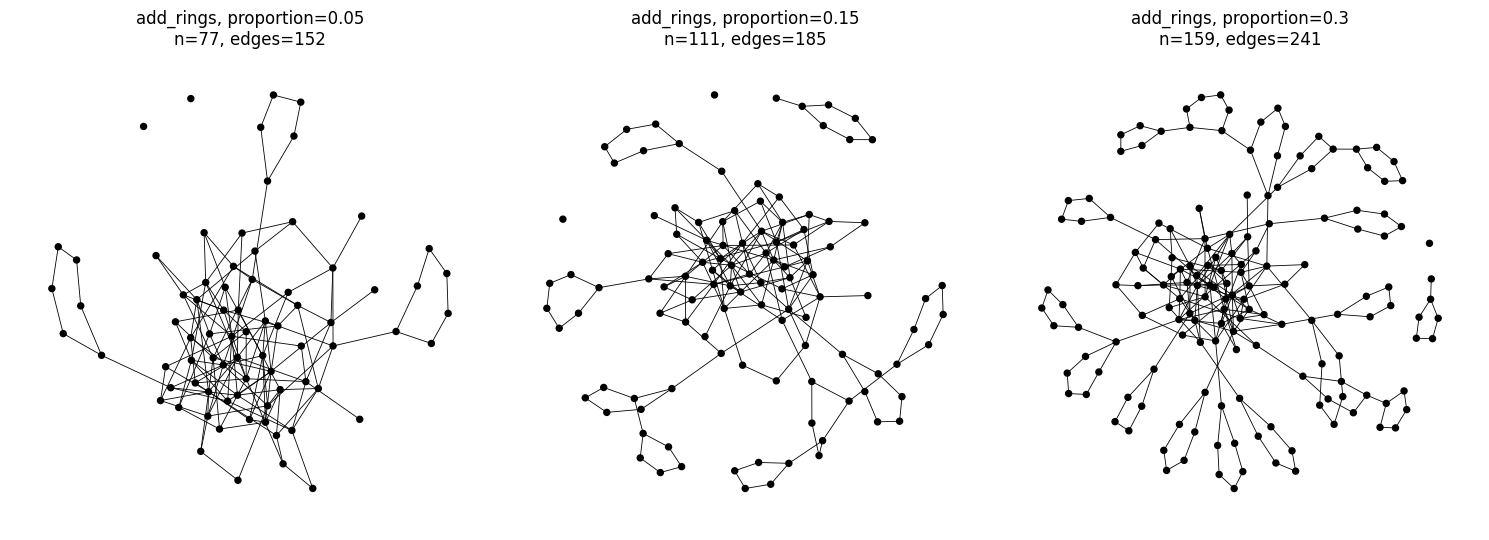

In [8]:
proportions = [0.05, 0.15, 0.3]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, prop in zip(axes, proportions):
    gr = sample_graphette(W, rho_n=rho, graph_edit_f="add_rings", n=60, t_or_p=prop,
                           ring_sizes=(5, 6), rng=rng)
    plot_graph(gr, ax, f"add_rings, proportion={prop}\nn={gr.vcount()}, edges={gr.ecount()}",
               color_by_degree=False)
plt.tight_layout()
plt.show()

Each little pentagon/hexagon dangling off the main cluster is an added ring, connected by a single bridge edge -- more of them appear as `proportion` increases. Ring structures are more common in molecular graphs. 

## 4. Star and ring together, at different sparsity levels

Finally, a 2x2 grid combining everything: dense vs. sparse base graphon, each with both star and ring edits applied one after the other.

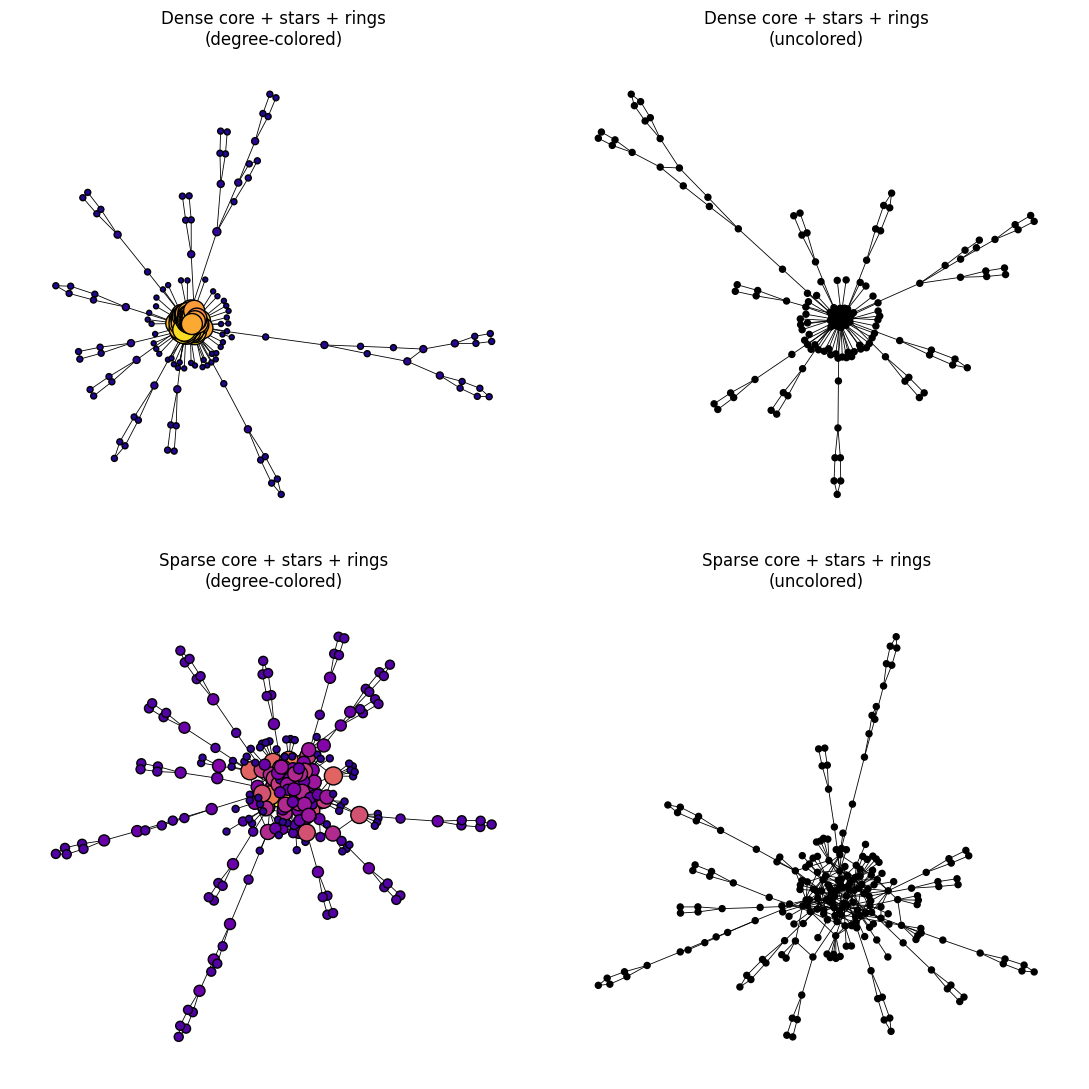

In [9]:
from Graphon_Mixtures_Graphettes import add_rings

def star_then_ring(W, rho_n, n, t, ring_prop, rng):
    gr = sample_graphette(W, rho_n=rho_n, graph_edit_f="star_f1", n=n, t_or_p=t, rng=rng)
    return add_rings(gr, proportion=ring_prop, ring_sizes=(5, 6), rng=rng)


fig, axes = plt.subplots(2, 2, figsize=(11, 11))
configs = [
    (None, "Dense core"),
    (lambda k: 8.0 / k, "Sparse core"),
]
for row, (rho_n, label) in enumerate(configs):
    gr = star_then_ring(W, rho_n, n=90, t=5, ring_prop=0.1, rng=rng)
    plot_graph(gr, axes[row][0], f"{label} + stars + rings\n(degree-colored)")
    plot_graph(gr, axes[row][1], f"{label} + stars + rings\n(uncolored)", color_by_degree=False)
plt.tight_layout()
plt.show()

## Recap

- `sample_sparse_graphon(W, rho_n, n)` samples from a rescaled graphon $\rho_n(n) \cdot W$ -- the basic dense/sparse control.
- `sample_graphette(W, rho_n, graph_edit_f, n, t_or_p, ring_sizes)` adds an optional structural edit on top:
  - `'star_f1'`..`'star_f5'` graft Poisson-random hub structure (strength `t_or_p`) onto existing nodes,
  - `'add_rings'` adds in small cycles (`t_or_p` = proportion of nodes worth of rings to add),
  - `'remove_cycles'` collapses the graph to a spanning tree/forest.

Try swapping in `star_f2`..`star_f5` above (each has a different hub-intensity profile -- constant, shifted exponential, etc.), or a different base graphon (e.g. `sbm_graphon` or `create_exp_matrix`), to explore other combinations.